# Weighing the Black Hole at the Centre of the Milky Way — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Every figure of the guide is produced here and saved in `images/`.

**Data (real):** 25 years of infrared astrometry and spectroscopy of the S-stars orbiting Sgr A*
(NTT, VLT, Keck; Gillessen et al. 2017, ApJ 837, 30, table 5, via CDS VizieR).

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
import urllib.request

DATASETS_PATH = os.path.join("datasets", "sstars")
CATALOG = "J/ApJ/837/30"            # Gillessen et al. (2017) in the CDS VizieR service
VIZIER_MIRRORS = ["https://vizier.cds.unistra.fr", "https://vizier.cfa.harvard.edu",
                  "https://vizier.idia.ac.za"]

def fetch_vizier_table(table, filename, path=DATASETS_PATH):
    """Download a VizieR table as tab-separated values (tries several mirrors)."""
    os.makedirs(path, exist_ok=True)
    tsv_path = os.path.join(path, filename)
    if os.path.exists(tsv_path):
        return tsv_path
    query = f"/viz-bin/asu-tsv?-source={CATALOG}/{table}&-out.all&-out.max=unlimited"
    for mirror in VIZIER_MIRRORS:
        try:
            text = urllib.request.urlopen(mirror + query, timeout=60).read().decode()
            break
        except Exception as error:
            print("mirror failed:", mirror, error)
    with open(tsv_path, "w") as f:
        f.write(text)
    return tsv_path

def load_vizier_tsv(tsv_path):
    """VizieR TSV = '#' comment lines, a header, a units line, a dashes line, data."""
    lines = [l.rstrip("\n") for l in open(tsv_path) if not l.startswith("#") and l.strip()]
    header = lines[0].split("\t")
    rows = [l.split("\t") for l in lines[3:]]
    df = pd.DataFrame(rows, columns=header).replace(r"^\s*$", np.nan, regex=True)
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() == df[col].notna().sum():   # purely numeric column
            df[col] = converted
        else:
            df[col] = df[col].str.strip()
    return df

raw = load_vizier_tsv(fetch_vizier_table("table5", "gillessen2017_table5.tsv"))
raw.iloc[:5, :16]

,recno,Date,Flag,oRA-S1,e_oRA-S1,oDE-S1,e_oDE-S1,RV-S1,e_RV-S1,oRA-S2,e_oRA-S2,oDE-S2,e_oDE-S2,RV-S2,e_RV-S2,oRA-S4
0,1,1992.224,a,-179.1,4.5,179.8,4.5,NaN,NaN,-9.9,3.7,170.2,3.8,NaN,NaN,97.9
1,2,1994.314,a,-178.4,8.5,97.9,2.5,NaN,NaN,-33.7,3.7,177.5,2.9,NaN,NaN,NaN
2,3,1995.534,a,-167.5,5.5,49.6,4.9,NaN,NaN,-41.8,3.0,170.3,3.5,NaN,NaN,158.4
3,4,1996.253,a,-161.2,10.0,21.4,8.7,NaN,NaN,-47.6,2.9,162.2,2.6,NaN,NaN,NaN
4,5,1996.427,a,-151.7,5.1,9.8,6.6,NaN,NaN,-50.3,1.7,160.2,4.4,NaN,NaN,NaN


In [3]:
raw.shape, raw["Inst"].value_counts().to_dict(), raw["Flag"].value_counts().to_dict()

((216, 106),
 {'VLT': 201, 'NTT': 11, 'Keck': 3, 'GEMINI': 1},
 {'a': 168, 'rv': 48})

In [4]:
def tidy_observations(raw):
    """Wide table (one column group per star) -> one row per star and epoch."""
    stars = [c[4:] for c in raw.columns if c.startswith("oRA-")]
    frames = []
    for star in stars:
        cols = {f"oRA-{star}": "x", f"e_oRA-{star}": "x_err", f"oDE-{star}": "y",
                f"e_oDE-{star}": "y_err", f"RV-{star}": "rv", f"e_RV-{star}": "rv_err"}
        part = raw[["Date", "Flag", "Inst"] + list(cols)].rename(columns=cols)
        part = part.dropna(subset=["x", "rv"], how="all")
        frames.append(part.assign(star=star))
    obs = pd.concat(frames, ignore_index=True)
    return obs.rename(columns={"Date": "date", "Flag": "kind", "Inst": "inst"})

obs = tidy_observations(raw)
obs.head()

,date,kind,inst,x,x_err,y,y_err,rv,rv_err,star
0,1992.224,a,NTT,-179.1,4.5,179.8,4.5,NaN,NaN,S1
1,1994.314,a,NTT,-178.4,8.5,97.9,2.5,NaN,NaN,S1
2,1995.534,a,NTT,-167.5,5.5,49.6,4.9,NaN,NaN,S1
3,1996.253,a,NTT,-161.2,10.0,21.4,8.7,NaN,NaN,S1
4,1996.427,a,NTT,-151.7,5.1,9.8,6.6,NaN,NaN,S1


In [5]:
obs.info()

<class 'pandas.DataFrame'>
RangeIndex: 2585 entries, 0 to 2584
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    2585 non-null   float64
 1   kind    2585 non-null   str    
 2   inst    2585 non-null   str    
 3   x       2232 non-null   float64
 4   x_err   2232 non-null   float64
 5   y       2232 non-null   float64
 6   y_err   2232 non-null   float64
 7   rv      353 non-null    float64
 8   rv_err  353 non-null    float64
 9   star    2585 non-null   str    
dtypes: float64(7), str(3)
memory usage: 202.1 KB


In [6]:
obs.groupby("star")["kind"].value_counts().unstack(fill_value=0).sort_values("a", ascending=False).T

star,S8,S1,S9,S12,S31,S17,S21,S2,S18,S4,S24,S13,S38,S19,S14,S54,S55
kind,,,,,,,,,,,,,,,,,
a,166,161,160,158,155,150,146,145,142,136,130,127,114,105,99,94,44
rv,29,29,22,27,24,30,17,44,12,34,22,22,5,19,12,3,2


In [7]:
s2 = obs[obs["star"] == "S2"].copy()
s2.describe()

,date,x,x_err,y,y_err,rv,rv_err
count,189.000000,145.000000,145.000000,145.000000,145.000000,44.000000,44.000000
mean,2008.215344,-17.901379,0.967586,134.140690,0.940690,-264.113636,46.636364
std,4.846143,35.501639,1.255703,51.143604,1.201995,729.837166,17.609578
min,1992.224000,-71.200000,0.300000,-14.400000,0.300000,-1571.000000,17.000000
25%,2004.535000,-48.000000,0.400000,111.100000,0.400000,-844.250000,34.000000
50%,2009.273000,-29.000000,0.400000,155.600000,0.400000,-453.500000,45.000000
75%,2011.695000,23.000000,0.700000,175.100000,0.700000,224.500000,57.000000
max,2016.530000,39.100000,9.000000,179.600000,8.400000,1199.000000,113.000000


Saving figure s2_attribute_histograms


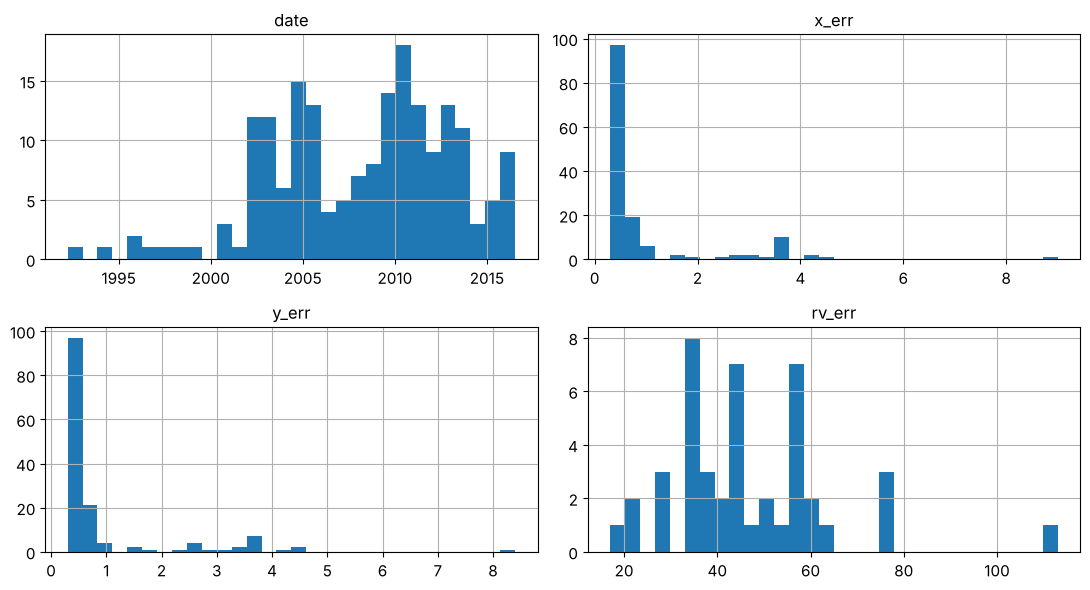

In [8]:
s2[["date", "x_err", "y_err", "rv_err"]].hist(bins=30, figsize=(11, 6))
save_fig("s2_attribute_histograms")
plt.show()

## Create a Test Set

In [9]:
s2["r"] = np.hypot(s2["x"], s2["y"])          # projected distance from Sgr A* (mas)
s2["r_cat"] = pd.cut(s2["r"], bins=[0, 60, 120, 160, np.inf], labels=[1, 2, 3, 4])
s2["rv_cat"] = pd.cut(s2["rv"].abs(), bins=[0, 500, 1000, np.inf], labels=[1, 2, 3])
s2["r_cat"].value_counts().sort_index()

r_cat
1    11
2    26
3    33
4    75
Name: count, dtype: int64

In [10]:
from sklearn.model_selection import StratifiedShuffleSplit

def stratified_split(df, cat_col, test_size=0.2, seed=42):
    split = StratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(split.split(df, df[cat_col]))
    return df.iloc[train_idx], df.iloc[test_idx]

astro = s2[s2["kind"] == "a"]
spectro = s2[s2["kind"] == "rv"]
astro_train, astro_test = stratified_split(astro, "r_cat")
rv_train, rv_test = stratified_split(spectro, "rv_cat")
train_set = pd.concat([astro_train, rv_train]).sort_values("date")
test_set = pd.concat([astro_test, rv_test]).sort_values("date")
len(train_set), len(test_set)

(151, 38)

In [11]:
from sklearn.model_selection import train_test_split

def cat_proportions(data):
    return data["r_cat"].value_counts() / len(data)

rnd_train, rnd_test = train_test_split(astro, test_size=0.2, random_state=42)
compare = pd.DataFrame({"Overall": cat_proportions(astro),
                        "Stratified": cat_proportions(astro_test),
                        "Random": cat_proportions(rnd_test)}).sort_index()
compare["Rand. %error"] = 100 * compare["Random"] / compare["Overall"] - 100
compare["Strat. %error"] = 100 * compare["Stratified"] / compare["Overall"] - 100
compare.round(3)

,Overall,Stratified,Random,Rand. %error,Strat. %error
r_cat,,,,,
1,0.076,0.069,0.138,81.818,-9.091
2,0.179,0.172,0.138,-23.077,-3.846
3,0.228,0.241,0.241,6.061,6.061
4,0.517,0.517,0.483,-6.667,0.000


## Discover and Visualize the Data to Gain Insights

Saving figure sstars_sky_plot


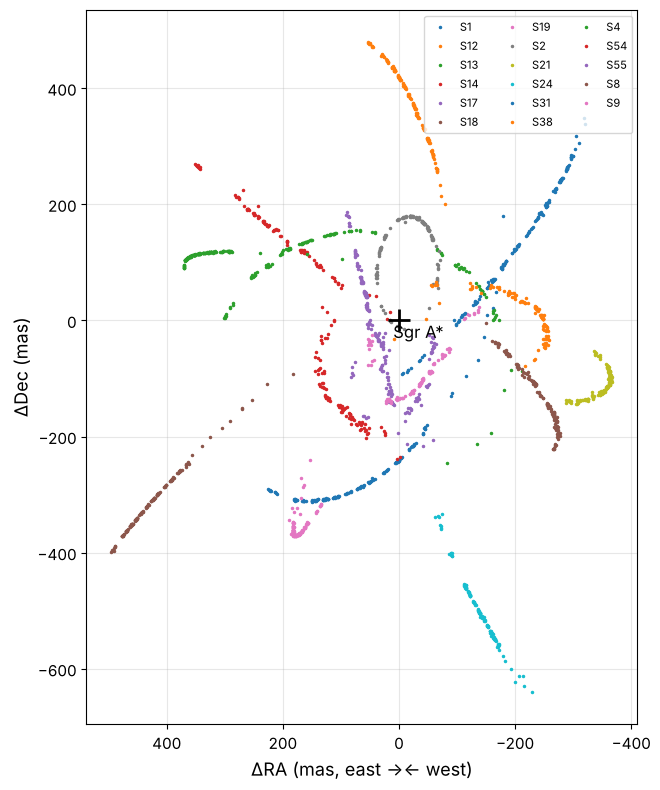

In [12]:
astrometry = obs[obs["kind"] == "a"]
fig, ax = plt.subplots(figsize=(8, 8))
for star, track in astrometry.groupby("star"):
    ax.plot(track["x"], track["y"], ".", ms=3, label=star)
ax.plot(0, 0, "k+", ms=16, mew=2)
ax.text(10, -30, "Sgr A*", fontsize=12)
ax.invert_xaxis()                       # east is to the left on the sky
ax.set_xlabel("ΔRA (mas, east →← west)"); ax.set_ylabel("ΔDec (mas)")
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.legend(ncol=3, fontsize=8, loc="upper right")
save_fig("sstars_sky_plot")
plt.show()

Saving figure s2_sky_orbit_plot


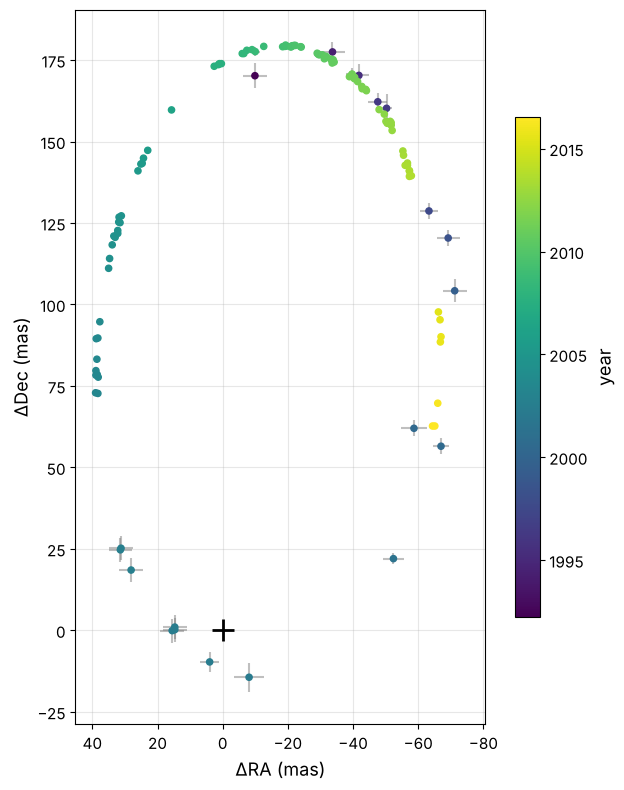

In [13]:
s2_train = train_set.copy()
s2_astro = s2_train[s2_train["kind"] == "a"]
fig, ax = plt.subplots(figsize=(6.5, 8))
sc = ax.scatter(s2_astro["x"], s2_astro["y"], c=s2_astro["date"], cmap="viridis", s=20, zorder=3)
ax.errorbar(s2_astro["x"], s2_astro["y"], xerr=s2_astro["x_err"], yerr=s2_astro["y_err"],
            fmt="none", ecolor="gray", alpha=0.5)
ax.plot(0, 0, "k+", ms=16, mew=2)
ax.invert_xaxis(); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("ΔRA (mas)"); ax.set_ylabel("ΔDec (mas)")
plt.colorbar(sc, label="year", shrink=0.7)
save_fig("s2_sky_orbit_plot")
plt.show()

Saving figure s2_radial_velocity_plot


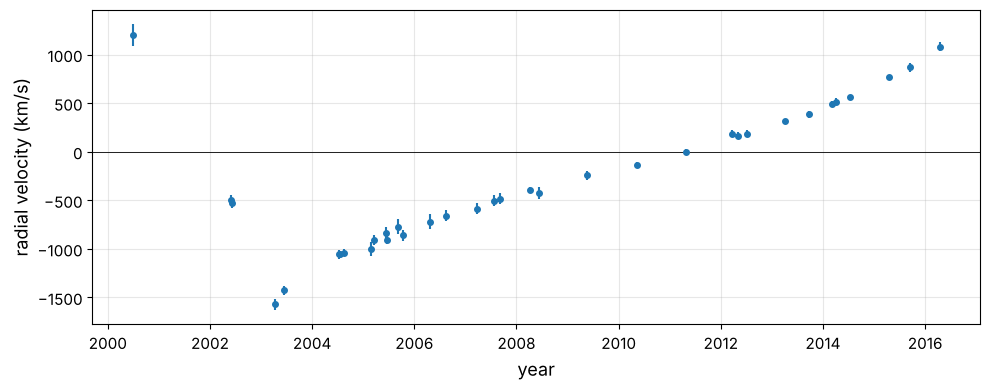

In [14]:
s2_rv = s2_train[s2_train["kind"] == "rv"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(s2_rv["date"], s2_rv["rv"], yerr=s2_rv["rv_err"], fmt="o", ms=4)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("year"); ax.set_ylabel("radial velocity (km/s)")
ax.grid(alpha=0.3)
save_fig("s2_radial_velocity_plot")
plt.show()

In [15]:
def local_accelerations(track, window=3.0, step=0.5, min_points=7):
    """Fit x(t), y(t) with quadratics in sliding windows -> acceleration vectors."""
    rows = []
    t = track["date"].values
    for t0 in np.arange(t.min() + window / 2, t.max() - window / 2 + 1e-9, step):
        sel = np.abs(t - t0) <= window / 2
        if sel.sum() < min_points:
            continue
        dt = t[sel] - t0
        out = {"star": track["star"].iloc[0], "t": t0}
        for c in ("x", "y"):
            w = 1 / track[c + "_err"].values[sel]
            coef, cov = np.polyfit(dt, track[c].values[sel], 2, w=w, cov="unscaled")
            out[c] = coef[2]                        # position at t0
            out["a" + c] = 2 * coef[0]              # acceleration (mas/yr²)
            out["a" + c + "_err"] = 2 * np.sqrt(cov[0, 0])
        rows.append(out)
    return pd.DataFrame(rows)

acc = pd.concat([local_accelerations(tr) for _, tr in astrometry.groupby("star")
                 if len(tr) >= 10], ignore_index=True)
acc["r"] = np.hypot(acc["x"], acc["y"])
acc["a"] = np.hypot(acc["ax"], acc["ay"])
acc["snr"] = acc["a"] / np.hypot(acc["ax_err"], acc["ay_err"])
acc = acc[acc["snr"] > 5]
acc["cos_angle"] = -(acc["ax"] * acc["x"] + acc["ay"] * acc["y"]) / (acc["a"] * acc["r"])
print(len(acc), "significant accelerations from", acc["star"].nunique(), "stars")
acc[["star", "t", "r", "a", "snr", "cos_angle"]].round(2).head()

51 significant accelerations from 8 stars


,star,t,r,a,snr,cos_angle
4,S1,2003.22,212.10,4.96,6.56,0.97
5,S1,2003.72,223.68,4.90,6.91,0.95
6,S1,2004.22,234.62,3.72,5.82,1.00
7,S1,2004.72,245.40,3.90,5.86,0.99
8,S1,2005.22,255.79,4.65,6.61,1.00


Saving figure acceleration_vectors_plot


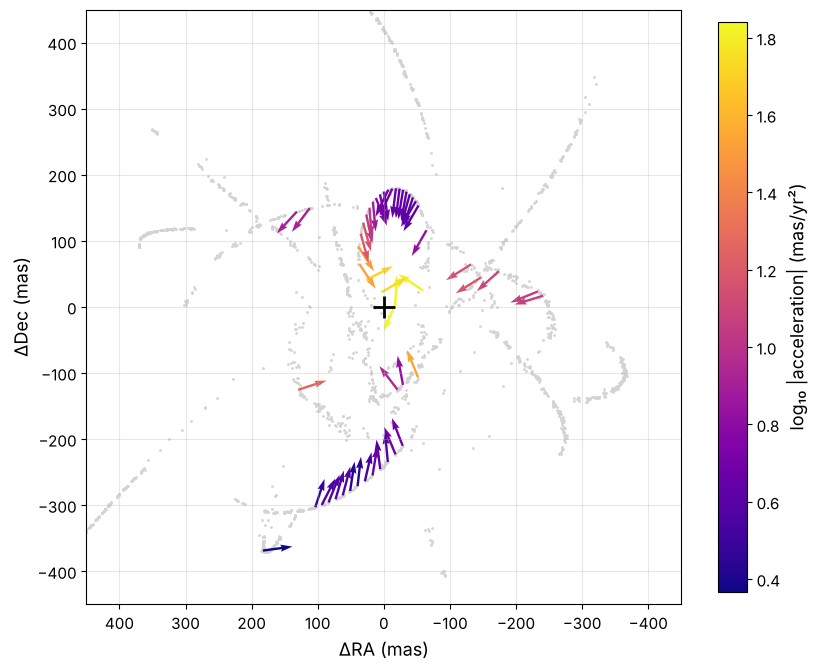

In [16]:
# Arrows of equal length show the *direction*; colour shows the *size* (log scale)
fig, ax = plt.subplots(figsize=(8.5, 8))
ux, uy = acc["ax"] / acc["a"], acc["ay"] / acc["a"]
q = ax.quiver(acc["x"], acc["y"], ux, uy, np.log10(acc["a"]), cmap="plasma",
              angles="xy", scale_units="xy", scale=1 / 45, width=0.004)
ax.plot(astrometry["x"], astrometry["y"], ".", color="lightgray", ms=2, zorder=0)
ax.plot(0, 0, "k+", ms=16, mew=2)
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlim(450, -450); ax.set_ylim(-450, 450)
ax.set_xlabel("ΔRA (mas)"); ax.set_ylabel("ΔDec (mas)")
plt.colorbar(q, label="log₁₀ |acceleration| (mas/yr²)", shrink=0.75)
save_fig("acceleration_vectors_plot")
plt.show()

In [17]:
acc[["r", "a", "cos_angle"]].corr()

,r,a,cos_angle
r,1.000000,-0.734511,0.409206
a,-0.734511,1.000000,-0.643720
cos_angle,0.409206,-0.643720,1.000000


Saving figure acceleration_vs_distance_plot


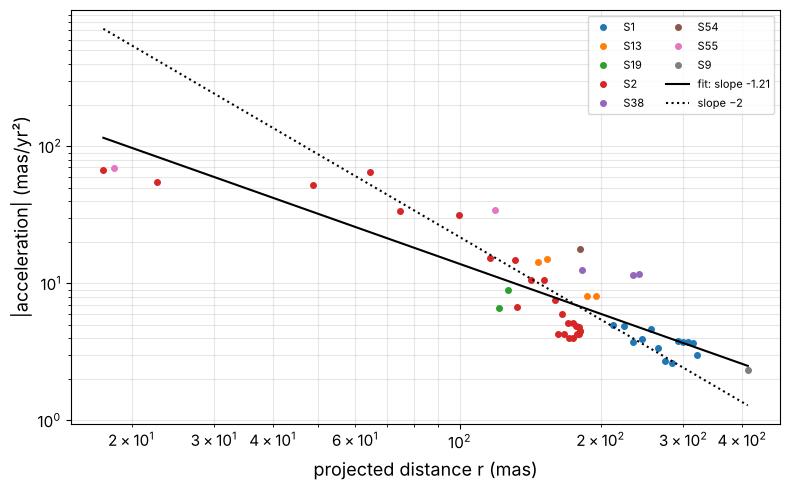

np.float64(-1.2114771249224088)

In [18]:
slope, intercept = np.polyfit(np.log10(acc["r"]), np.log10(acc["a"]), 1)
fig, ax = plt.subplots(figsize=(8, 5))
for star, grp in acc.groupby("star"):
    ax.loglog(grp["r"], grp["a"], "o", ms=4, label=star)
rr = np.logspace(np.log10(acc["r"].min()), np.log10(acc["r"].max()), 50)
ax.loglog(rr, 10**intercept * rr**slope, "k-", label=f"fit: slope {slope:.2f}")
ax.loglog(rr, 10**intercept * rr**-2 * np.median(acc["r"])**(slope + 2), "k:", label="slope −2")
ax.set_xlabel("projected distance r (mas)"); ax.set_ylabel("|acceleration| (mas/yr²)")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8, ncol=2)
save_fig("acceleration_vs_distance_plot")
plt.show()
slope

In [19]:
# a * r² should be constant (= G M / R0³ in angular units, if r were the true 3D distance)
acc["a_r2"] = acc["a"] * acc["r"] ** 2
acc.groupby("star")["a_r2"].median().sort_values() / 1e6

star
S19    0.119863
S2     0.148309
S1     0.245353
S55    0.255214
S13    0.307704
S9     0.394781
S54    0.575331
S38    0.628343
Name: a_r2, dtype: float64

In [20]:
# The *largest* a·r² values are the least affected by projection (see text)
mu_acc = acc["a_r2"].quantile(0.9)
print(f"G M / R0³ ≈ {mu_acc:.3g} mas³/yr²")
# Kepler III in these units: P² = 4π² a³ / (G M)  (a in mas, P in yr, angles!)
M_over_R0cube = mu_acc / (4 * np.pi**2)          # in mas³/yr² -> solar masses / kpc³
print(f"M / R0³ ≈ {M_over_R0cube:.3g} M_sun per kpc³  ->  M ≈ {M_over_R0cube * 8.0**3:.3g} M_sun if R0 = 8 kpc")

G M / R0³ ≈ 3.95e+05 mas³/yr²
M / R0³ ≈ 1e+04 M_sun per kpc³  ->  M ≈ 5.12e+06 M_sun if R0 = 8 kpc


## Prepare the Data for Machine Learning Algorithms

In [21]:
s2_train = train_set.copy()

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin

KIND_RA, KIND_DEC, KIND_RV = 0, 1, 2

class ObservationStacker(BaseEstimator, TransformerMixin):
    """One row per epoch (x, y or rv)  ->  one row per *measured number*:
    features = [time, kind code, uncertainty]; target = the number."""
    def __init__(self, error_floor=0.0, rv_error_floor=0.0):
        self.error_floor = error_floor            # mas, added in quadrature
        self.rv_error_floor = rv_error_floor      # km/s
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        parts = []
        a = X[X["kind"] == "a"]
        for code, col in ((KIND_RA, "x"), (KIND_DEC, "y")):
            err = np.hypot(a[col + "_err"], self.error_floor)
            parts.append(np.c_[a["date"], np.full(len(a), code), err, a[col]])
        v = X[X["kind"] == "rv"]
        err = np.hypot(v["rv_err"], self.rv_error_floor)
        parts.append(np.c_[v["date"], np.full(len(v), KIND_RV), err, v["rv"]])
        return np.vstack(parts)

stacked = ObservationStacker().fit_transform(s2_train)
X_train, y_train = stacked[:, :3], stacked[:, 3]
pd.DataFrame(stacked[[0, 1, -1]], columns=["time", "kind", "error", "value"])

,time,kind,error,value
0,1992.224,0.0,3.7,-9.9
1,1994.314,0.0,3.7,-33.7
2,2016.284,2.0,45.0,1081.0


In [23]:
from sklearn.preprocessing import OneHotEncoder

kind_encoder = OneHotEncoder()
kind_1hot = kind_encoder.fit_transform(X_train[:, [1]])
kind_encoder.categories_, kind_1hot.toarray()[[0, -1]]

([array([0., 1., 2.])],
 array([[1., 0., 0.],
        [0., 0., 1.]]))

## Select and Train a Model

In [24]:
def chi2_per_point(y_true, y_pred, err):
    """Mean squared *normalized* residual: ~1 if the model is right."""
    return np.mean(((y_true - y_pred) / err) ** 2)

In [25]:
from sklearn.base import RegressorMixin
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

class PolynomialTrackRegressor(BaseEstimator, RegressorMixin):
    """Baseline: an independent weighted polynomial in time for each kind of data."""
    def __init__(self, degree=3):
        self.degree = degree
    def fit(self, X, y):
        self.models_ = {}
        for kind in np.unique(X[:, 1]):
            sel = X[:, 1] == kind
            t = (X[sel, 0] - 2005) / 10
            model = make_poly(self.degree).fit(t.reshape(-1, 1), y[sel],
                                               lin__sample_weight=1 / X[sel, 2] ** 2)
            self.models_[kind] = model
        return self
    def predict(self, X):
        out = np.empty(len(X))
        for kind, model in self.models_.items():
            sel = X[:, 1] == kind
            if sel.any():
                out[sel] = model.predict(((X[sel, 0] - 2005) / 10).reshape(-1, 1))
        return out
    def score(self, X, y):
        return -chi2_per_point(y, self.predict(X), X[:, 2])

from sklearn.pipeline import Pipeline
def make_poly(degree):
    return Pipeline([("poly", PolynomialFeatures(degree, include_bias=False)),
                     ("lin", LinearRegression())])

for degree in (2, 5, 10):
    poly_reg = PolynomialTrackRegressor(degree).fit(X_train, y_train)
    print(f"degree {degree:2d}: training chi2 per point = {-poly_reg.score(X_train, y_train):10.2f}")

degree  2: training chi2 per point =     666.13
degree  5: training chi2 per point =     114.49
degree 10: training chi2 per point =      16.76


In [26]:
AU_YR_IN_KMS = 4.740470463          # 1 AU per year in km/s

def solve_kepler(M, e, n_iter=60):
    """E - e sin E = M (Newton's method, safe for e up to ~0.99)."""
    E = M + e * np.sin(M)
    E = np.where(e > 0.8, np.pi * np.ones_like(M), E)        # better start for big e
    for _ in range(n_iter):
        E = E - (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    return E

def orbit_model(params, t):
    """Sky offsets (mas) and radial velocity (km/s) of a star on a Kepler orbit.
    params: a (mas), e, i, Omega, omega (deg), t_peri (yr), P (yr), R0 (kpc),
            x0, y0 (mas), vx, vy (mas/yr), vz0 (km/s)"""
    a, e, inc, Om, om, tp, P, R0, x0, y0, vx, vy, vz0 = params
    i, O, w = np.radians([inc, Om, om])
    M = np.mod(2 * np.pi * (t - tp) / P, 2 * np.pi)
    E = solve_kepler(M, e)
    X, Y = np.cos(E) - e, np.sqrt(1 - e * e) * np.sin(E)      # in units of a
    # Thiele-Innes constants: rotate the orbit (i, Omega, omega) onto the sky
    A = a * (np.cos(w) * np.cos(O) - np.sin(w) * np.sin(O) * np.cos(i))
    B = a * (np.cos(w) * np.sin(O) + np.sin(w) * np.cos(O) * np.cos(i))
    F = a * (-np.sin(w) * np.cos(O) - np.cos(w) * np.sin(O) * np.cos(i))
    G = a * (-np.sin(w) * np.sin(O) + np.cos(w) * np.cos(O) * np.cos(i))
    dec = A * X + F * Y + y0 + vy * (t - 2009.0)
    ra = B * X + G * Y + x0 + vx * (t - 2009.0)
    # velocity along the line of sight needs physical units: a[AU] = a[mas] * R0[kpc]
    Edot = 2 * np.pi / P / (1 - e * np.cos(E))
    Xdot, Ydot = -np.sin(E) * Edot, np.sqrt(1 - e * e) * np.cos(E) * Edot
    vz = a * R0 * (np.sin(w) * np.sin(i) * Xdot + np.cos(w) * np.sin(i) * Ydot) * AU_YR_IN_KMS
    return ra, dec, vz + vz0

In [27]:
from scipy.optimize import least_squares

ORBIT_PARAMS = ["a", "e", "i", "Omega", "omega", "t_peri", "P", "R0",
                "x0", "y0", "vx", "vy", "vz0"]
LOWER = [50, 0.0, 0, -360, -360, 1995, 10, 4, -20, -20, -5, -5, -200]
UPPER = [250, 0.99, 180, 720, 720, 2010, 25, 12, 20, 20, 5, 5, 200]

class KeplerOrbitRegressor(BaseEstimator, RegressorMixin):
    """Fits a Kepler orbit around a point mass to stacked [time, kind, error] data.
    fit_drift: also fit the slow drift (vx, vy) of the reference frame."""
    def __init__(self, fit_drift=True, n_starts=1, init=None, random_state=42):
        self.fit_drift = fit_drift
        self.n_starts = n_starts
        self.init = init
        self.random_state = random_state

    def _predict(self, q, X):
        ra, dec, rv = orbit_model(q, X[:, 0])
        return np.select([X[:, 1] == KIND_RA, X[:, 1] == KIND_DEC], [ra, dec], rv)

    def fit(self, X, y):
        rng = np.random.RandomState(self.random_state)
        free = np.ones(len(ORBIT_PARAMS), bool)
        if not self.fit_drift:
            free[[ORBIT_PARAMS.index("vx"), ORBIT_PARAMS.index("vy")]] = False
        best = None
        for k in range(self.n_starts):
            if self.init is not None and k == 0:
                q0 = np.array([self.init[p] for p in ORBIT_PARAMS], float)
            else:    # random guess: S2 is clearly on a ~16-yr, very elongated orbit
                q0 = np.array([rng.uniform(100, 150), rng.uniform(0.6, 0.95), rng.uniform(0, 180),
                               rng.uniform(0, 360), rng.uniform(0, 360), rng.uniform(2000, 2004),
                               rng.uniform(14, 18), 8.0, 0, 0, 0, 0, 0])
            if not self.fit_drift:
                q0[[10, 11]] = 0.0
            def residuals(z):
                q = q0.copy(); q[free] = z
                return (y - self._predict(q, X)) / X[:, 2]
            res = least_squares(residuals, q0[free], bounds=(np.array(LOWER)[free],
                                np.array(UPPER)[free]), x_scale="jac", max_nfev=3000)
            if best is None or res.cost < best[0].cost:
                q = q0.copy(); q[free] = res.x
                best = (res, q)
        self.result_, self.q_ = best
        self.params_ = dict(zip(ORBIT_PARAMS, self.q_))
        return self

    def predict(self, X):
        return self._predict(self.q_, X)

    def score(self, X, y):
        return -chi2_per_point(y, self.predict(X), X[:, 2])

In [28]:
kepler_reg = KeplerOrbitRegressor(n_starts=40)
kepler_reg.fit(X_train, y_train)
print(f"training chi2 per point = {-kepler_reg.score(X_train, y_train):.3f}")
pd.Series(kepler_reg.params_).round(4)

training chi2 per point = 0.879


a          125.7287
e            0.8838
i          134.4257
Omega      226.3458
omega       65.1004
t_peri    2002.3292
P           16.1026
R0           8.2511
x0           0.9324
y0          -1.3206
vx           0.0944
vy           0.0081
vz0         29.2196
dtype: float64

In [29]:
def black_hole_mass(params):
    a_AU = params["a"] * params["R0"]               # mas * kpc = AU (definition of the parsec)
    return a_AU**3 / params["P"]**2                 # Kepler III in solar units: M = a³/P²

print(f"M = {black_hole_mass(kepler_reg.params_) / 1e6:.3f} million solar masses, "
      f"R0 = {kepler_reg.params_['R0']:.3f} kpc")

M = 4.306 million solar masses, R0 = 8.251 kpc


In [30]:
from sklearn.model_selection import KFold, cross_val_score

def display_scores(scores):
    print("Scores:", np.round(scores, 2))
    print("Mean:", np.round(scores.mean(), 3))
    print("Standard deviation:", np.round(scores.std(), 3))

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
for name, reg in [("polynomial deg 10", PolynomialTrackRegressor(10)),
                  ("polynomial deg 5", PolynomialTrackRegressor(5)),
                  ("Kepler orbit", KeplerOrbitRegressor(init=kepler_reg.params_))]:
    scores = -cross_val_score(reg, X_train, y_train, cv=kfold)
    print(f"--- {name} ---"); display_scores(scores)

--- polynomial deg 10 ---
Scores: [11527.92 14593.3    254.36  7038.02    32.45]
Mean: 6689.209
Standard deviation: 5860.532
--- polynomial deg 5 ---
Scores: [248.36 472.48 144.56 114.31 110.66]
Mean: 218.072
Standard deviation: 136.636


--- Kepler orbit ---
Scores: [1.12 1.05 3.21 1.26 1.13]
Mean: 1.552
Standard deviation: 0.831


polynomial deg 5  : chi2 per point on 2011-2016 =     539729.3
Kepler orbit      : chi2 per point on 2011-2016 =          4.9
Saving figure forecast_comparison_plot


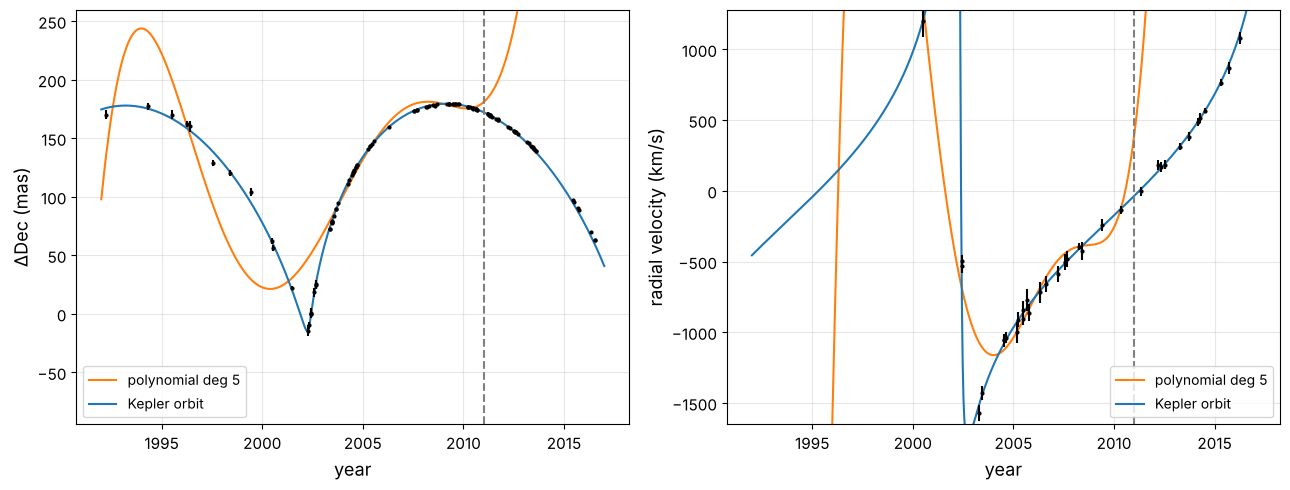

In [31]:
# A harder test: learn from the data before 2011, predict 2011-2016.
past = X_train[:, 0] < 2011
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t_plot = np.linspace(1992, 2017, 600)
for name, reg, color in [("polynomial deg 5", PolynomialTrackRegressor(5), "tab:orange"),
                         ("Kepler orbit", KeplerOrbitRegressor(init=kepler_reg.params_), "tab:blue")]:
    reg.fit(X_train[past], y_train[past])
    future_chi2 = -reg.score(X_train[~past], y_train[~past])
    print(f"{name:18s}: chi2 per point on 2011-2016 = {future_chi2:12.1f}")
    for ax, kind in zip(axes, (KIND_DEC, KIND_RV)):
        Xp = np.c_[t_plot, np.full_like(t_plot, kind), np.ones_like(t_plot)]
        ax.plot(t_plot, reg.predict(Xp), color=color, label=name)
for ax, kind, label in zip(axes, (KIND_DEC, KIND_RV), ("ΔDec (mas)", "radial velocity (km/s)")):
    sel = X_train[:, 1] == kind
    ax.errorbar(X_train[sel, 0], y_train[sel], yerr=X_train[sel, 2], fmt="k.", ms=4)
    ax.axvline(2011, color="gray", ls="--")
    ax.set_ylim(np.min(y_train[sel]) - 80, np.max(y_train[sel]) + 80)
    ax.set_xlabel("year"); ax.set_ylabel(label); ax.grid(alpha=0.3); ax.legend()
save_fig("forecast_comparison_plot")
plt.show()

## Fine-Tune Your Model

In [32]:
from sklearn.model_selection import GridSearchCV

class TunedOrbit(BaseEstimator, RegressorMixin):
    """Pipeline-like wrapper so the error floors become tunable hyperparameters,
    while the *score* always uses the original (published) uncertainties."""
    def __init__(self, error_floor=0.0, rv_error_floor=0.0, fit_drift=True, init=None):
        self.error_floor = error_floor
        self.rv_error_floor = rv_error_floor
        self.fit_drift = fit_drift
        self.init = init
    def _inflate(self, X):
        Xw = X.copy()
        floor = np.where(X[:, 1] == KIND_RV, self.rv_error_floor, self.error_floor)
        Xw[:, 2] = np.hypot(X[:, 2], floor)
        return Xw
    def fit(self, X, y):
        self.model_ = KeplerOrbitRegressor(fit_drift=self.fit_drift, init=self.init)
        self.model_.fit(self._inflate(X), y)
        return self
    def predict(self, X):
        return self.model_.predict(X)
    def score(self, X, y):
        return -chi2_per_point(y, self.predict(X), X[:, 2])

param_grid = {"error_floor": [0.0, 0.3, 1.0], "rv_error_floor": [0.0, 30.0],
              "fit_drift": [True, False]}
grid_search = GridSearchCV(TunedOrbit(init=kepler_reg.params_), param_grid, cv=kfold)
grid_search.fit(X_train, y_train)
grid_search.best_params_

{'error_floor': 1.0, 'fit_drift': False, 'rv_error_floor': 0.0}

In [33]:
cvres = grid_search.cv_results_
for score, params in sorted(zip(cvres["mean_test_score"], cvres["params"]),
                            key=lambda z: -z[0]):
    print(f"{-score:7.3f}", params)

  1.097 {'error_floor': 1.0, 'fit_drift': False, 'rv_error_floor': 0.0}
  1.115 {'error_floor': 1.0, 'fit_drift': True, 'rv_error_floor': 0.0}
  1.121 {'error_floor': 1.0, 'fit_drift': True, 'rv_error_floor': 30.0}
  1.127 {'error_floor': 1.0, 'fit_drift': False, 'rv_error_floor': 30.0}
  1.372 {'error_floor': 0.3, 'fit_drift': True, 'rv_error_floor': 0.0}
  1.404 {'error_floor': 0.3, 'fit_drift': True, 'rv_error_floor': 30.0}
  1.552 {'error_floor': 0.0, 'fit_drift': True, 'rv_error_floor': 0.0}
  1.589 {'error_floor': 0.0, 'fit_drift': True, 'rv_error_floor': 30.0}
  1.659 {'error_floor': 0.3, 'fit_drift': False, 'rv_error_floor': 0.0}
  1.726 {'error_floor': 0.3, 'fit_drift': False, 'rv_error_floor': 30.0}
  1.941 {'error_floor': 0.0, 'fit_drift': False, 'rv_error_floor': 0.0}
  2.006 {'error_floor': 0.0, 'fit_drift': False, 'rv_error_floor': 30.0}


In [34]:
final_model = grid_search.best_estimator_
best = final_model.model_.params_
print(f"M  = {black_hole_mass(best) / 1e6:.3f} million solar masses")
print(f"R0 = {best['R0']:.3f} kpc")
pd.Series(best).round(4)

M  = 4.513 million solar masses
R0 = 8.526 kpc


a          123.5031
e            0.8816
i          135.1101
Omega      225.8599
omega       64.2655
t_peri    2002.3226
P           16.0837
R0           8.5256
x0           0.5293
y0          -0.3375
vx           0.0000
vy           0.0000
vz0         30.4952
dtype: float64

In [35]:
# How uncertain are M and R0? Refit on 100 bootstrap resamples of the training epochs.
rng = np.random.RandomState(42)
boot = []
for k in range(100):
    idx = rng.randint(0, len(X_train), len(X_train))
    reg = TunedOrbit(**{**grid_search.best_params_, "init": best}).fit(X_train[idx], y_train[idx])
    p = reg.model_.params_
    boot.append([black_hole_mass(p) / 1e6, p["R0"], p["a"], p["P"], p["e"]])
boot = pd.DataFrame(boot, columns=["M_million", "R0", "a", "P", "e"])
boot.describe().loc[["mean", "std", "min", "max"]].round(4)

,M_million,R0,a,P,e
mean,4.5679,8.5810,123.2615,16.0941,0.8805
std,0.1644,0.1705,1.2531,0.0432,0.0028
min,4.2374,8.2086,120.3354,16.0173,0.8717
max,5.1517,9.1452,125.6773,16.2120,0.8861


Saving figure mass_distance_bootstrap_plot


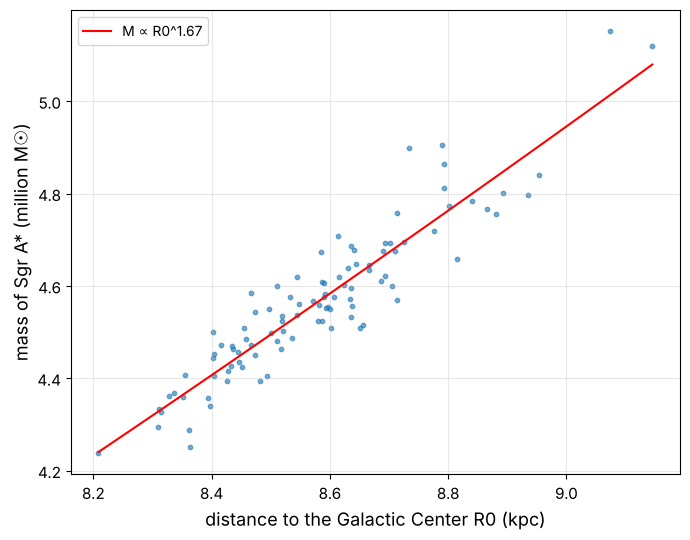

np.float64(1.6714555915521758)

In [36]:
k_deg, c_deg = np.polyfit(np.log(boot["R0"]), np.log(boot["M_million"]), 1)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(boot["R0"], boot["M_million"], s=10, alpha=0.6)
rr = np.linspace(boot["R0"].min(), boot["R0"].max(), 50)
ax.plot(rr, np.exp(c_deg) * rr**k_deg, "r-", label=f"M ∝ R0^{k_deg:.2f}")
ax.set_xlabel("distance to the Galactic Center R0 (kpc)")
ax.set_ylabel("mass of Sgr A* (million M☉)")
ax.grid(alpha=0.3); ax.legend()
save_fig("mass_distance_bootstrap_plot")
plt.show()
k_deg

Saving figure residual_pulls_plot


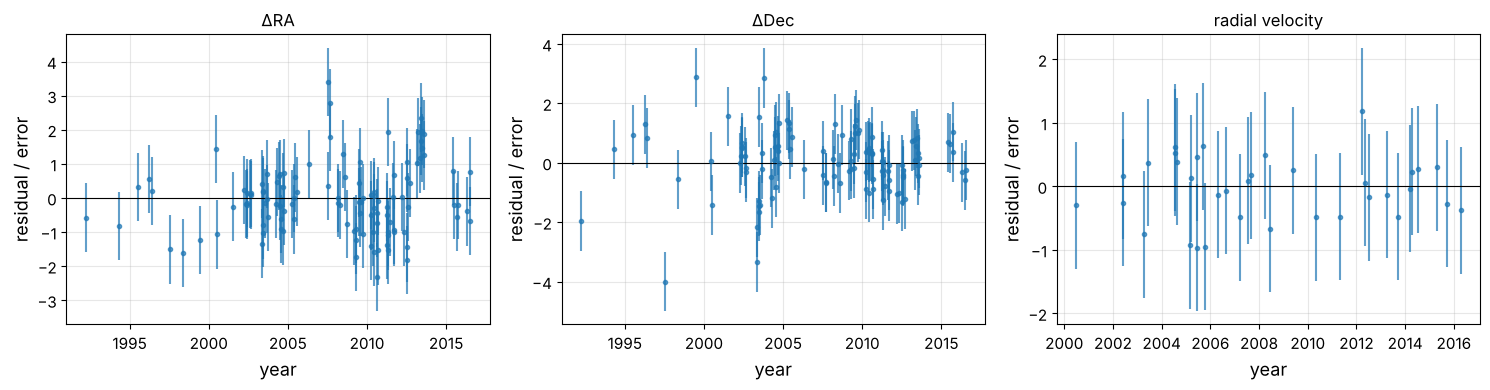

In [37]:
X_train_w = X_train
pred = final_model.predict(X_train)
pulls = (y_train - pred) / X_train[:, 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
names = ["ΔRA", "ΔDec", "radial velocity"]
for kind, ax in zip((KIND_RA, KIND_DEC, KIND_RV), axes):
    sel = X_train[:, 1] == kind
    ax.errorbar(X_train[sel, 0], pulls[sel], yerr=1, fmt="o", ms=3, alpha=0.7)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(names[kind]); ax.set_xlabel("year"); ax.set_ylabel("residual / error")
    ax.grid(alpha=0.3)
save_fig("residual_pulls_plot")
plt.show()

In [38]:
worst = pd.DataFrame({"year": X_train[:, 0], "kind": X_train[:, 1].astype(int),
                      "pull": pulls}).reindex(np.argsort(-np.abs(pulls)))
worst["kind"] = worst["kind"].map({0: "ΔRA", 1: "ΔDec", 2: "RV"})
worst.head(8).round(2)

,year,kind,pull
121,1997.54,ΔDec,-4.00
47,2007.55,ΔRA,3.41
136,2003.36,ΔDec,-3.34
123,1999.46,ΔDec,2.87
144,2003.76,ΔDec,2.86
48,2007.69,ΔRA,2.77
104,2013.44,ΔRA,2.36
75,2010.62,ΔRA,-2.32


## Evaluate Your System on the Test Set

In [39]:
test_stacked = ObservationStacker().transform(test_set)
X_test, y_test = test_stacked[:, :3], test_stacked[:, 3]
test_chi2 = -final_model.score(X_test, y_test)
print(f"test chi2 per point = {test_chi2:.3f}  ({len(y_test)} measured numbers)")
test_pulls = (y_test - final_model.predict(X_test)) / X_test[:, 2]
print(f"test RMS pull = {np.sqrt(np.mean(test_pulls**2)):.3f}")

test chi2 per point = 0.948  (67 measured numbers)
test RMS pull = 0.974


In [40]:
from scipy import stats

sq = test_pulls ** 2
interval = stats.t.interval(0.95, len(sq) - 1, loc=sq.mean(), scale=stats.sem(sq))
print(f"95% confidence interval for chi2 per point: ({interval[0]:.2f}, {interval[1]:.2f})")

95% confidence interval for chi2 per point: (0.38, 1.52)


Saving figure final_orbit_fit_plot


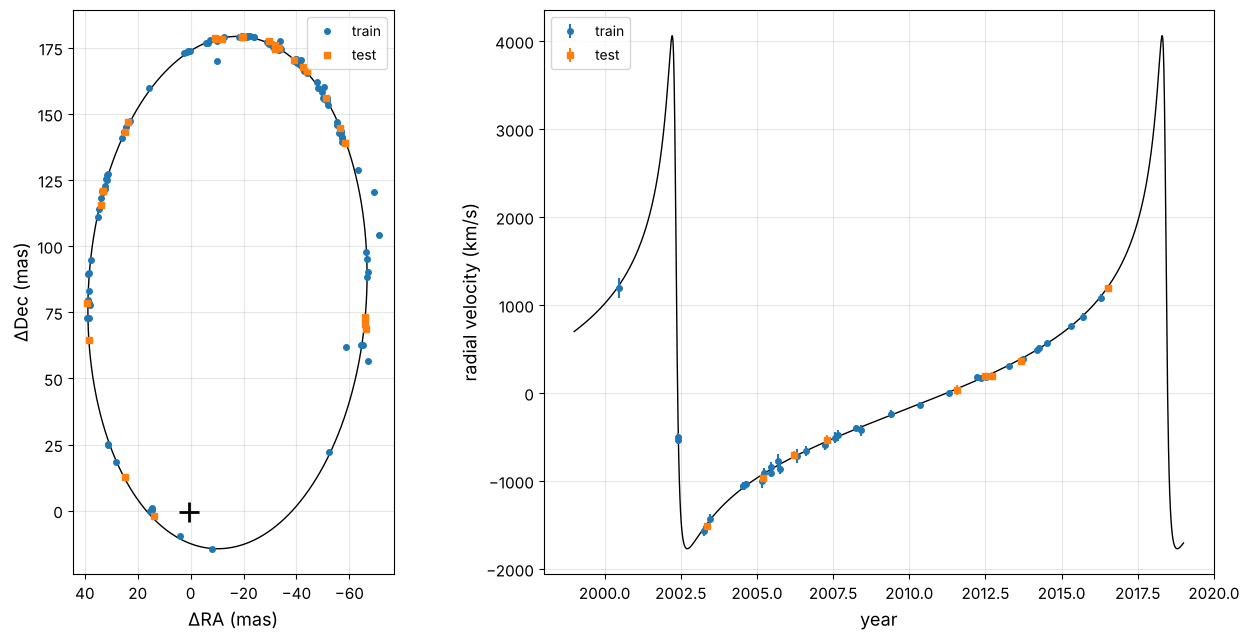

In [41]:
q = final_model.model_.q_
t_dense = np.linspace(best["t_peri"] - 0.5 * best["P"], best["t_peri"] + 0.5 * best["P"], 3000)
ra_m, dec_m, rv_m = orbit_model(q, t_dense)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.plot(ra_m, dec_m, "k-", lw=1)
for data, mk, lab in [(train_set, "o", "train"), (test_set, "s", "test")]:
    d = data[data["kind"] == "a"]
    ax.plot(d["x"], d["y"], mk, ms=4, label=lab)
ax.plot(best["x0"], best["y0"], "k+", ms=14, mew=2)
ax.invert_xaxis(); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_xlabel("ΔRA (mas)"); ax.set_ylabel("ΔDec (mas)")
ax = axes[1]
t_rv = np.linspace(1999, 2019, 2000)
ax.plot(t_rv, orbit_model(q, t_rv)[2], "k-", lw=1)
for data, mk, lab in [(train_set, "o", "train"), (test_set, "s", "test")]:
    d = data[data["kind"] == "rv"]
    ax.errorbar(d["date"], d["rv"], yerr=d["rv_err"], fmt=mk, ms=4, label=lab)
ax.set_xlabel("year"); ax.set_ylabel("radial velocity (km/s)"); ax.grid(alpha=0.3); ax.legend()
save_fig("final_orbit_fit_plot")
plt.show()

## Present Your Solution

In [42]:
G, c, M_SUN, AU = 6.674e-11, 2.998e8, 1.989e30, 1.496e11
M = black_hole_mass(best) * M_SUN
a_AU = best["a"] * best["R0"]
r_peri = a_AU * (1 - best["e"]) * AU
v_peri = np.sqrt(G * M * (1 + best["e"]) / r_peri)
r_s = 2 * G * M / c**2
print(f"semi-major axis        : {a_AU:7.0f} AU")
print(f"pericentre distance    : {r_peri / AU:7.0f} AU  ({r_peri / r_s:.0f} Schwarzschild radii)")
print(f"speed at pericentre    : {v_peri / 1e3:7.0f} km/s  ({100 * v_peri / c:.1f}% of c)")
print(f"Schwarzschild radius   : {r_s / AU:7.3f} AU  ({r_s / 1e9:.1f} million km)")
print(f"mean density within r_peri > {M / (4 / 3 * np.pi * r_peri**3) / M_SUN * AU**3 * 206265**3:.2e} M_sun/pc³")

semi-major axis        :    1053 AU
pericentre distance    :     125 AU  (1399 Schwarzschild radii)
speed at pericentre    :    7775 km/s  (2.6% of c)
Schwarzschild radius   :   0.089 AU  (13.3 million km)
mean density within r_peri > 4.88e+15 M_sun/pc³


In [43]:
# Fit every other star with its own, independent Kepler orbit (astrometry only).
# The centre and its drift are taken from S2; a and P are free for every star.
def fit_sky_orbit(track, center, n_starts=60, seed=0):
    t, ra, dec = track["date"].values, track["x"].values, track["y"].values
    era, edec = track["x_err"].values, track["y_err"].values
    def residuals(p):
        q = list(p[:5]) + [p[5], p[6], 8.0] + center + [0.0]
        r, d, _ = orbit_model(q, t)
        return np.r_[(ra - r) / era, (dec - d) / edec]
    rng = np.random.RandomState(seed)
    r_max = np.hypot(ra - center[0], dec - center[1]).max()
    best = None
    for _ in range(n_starts):
        P0 = 10 ** rng.uniform(1, 2.6)
        p0 = [r_max * rng.uniform(0.5, 1.5), rng.uniform(0, 0.95), rng.uniform(0, 180),
              rng.uniform(0, 360), rng.uniform(0, 360), rng.uniform(t.min() - P0, t.min() + P0), P0]
        res = least_squares(residuals, p0, x_scale="jac", max_nfev=500,
                            bounds=([5, 0, 0, -720, -720, 1500, 5], [3000, .99, 180, 720, 720, 2400, 2000]))
        if best is None or res.cost < best.cost:
            best = res
    a, e, i, Om, om, tp, P = best.x
    chi2_red = 2 * best.cost / (len(best.fun) - 7)
    cov = np.linalg.pinv(best.jac.T @ best.jac) * max(chi2_red, 1)
    grad = np.zeros(7); grad[0], grad[6] = 3 / a, -2 / P      # d log(a³/P²) / d params
    return {"a": a, "e": e, "i": i, "Omega": Om % 360, "omega": om % 360, "t_peri": tp, "P": P,
            "chi2_red": chi2_red, "n": len(t), "covered": t.max() - t.min(),
            "sigma_log_mu": np.sqrt(grad @ cov @ grad),
            "sigma_log_P": np.sqrt(cov[6, 6]) / P}

center = [best["x0"], best["y0"], best["vx"], best["vy"]]
fits = {}
for star in ["S1", "S4", "S8", "S9", "S12", "S13", "S14", "S18", "S31", "S38", "S55"]:
    track = astrometry[astrometry["star"] == star]
    fits[star] = fit_sky_orbit(track, center)
star_orbits = pd.DataFrame(fits).T.astype(float)
star_orbits.loc["S2"] = {**{k: best[k] for k in ["a", "e", "i", "P", "t_peri"]},
                         "Omega": best["Omega"] % 360, "omega": best["omega"] % 360}
star_orbits.loc["S2", "sigma_log_mu"] = 0.0
star_orbits[["a", "e", "P", "chi2_red", "covered", "sigma_log_mu"]].round(3)

,a,e,P,chi2_red,covered,sigma_log_mu
S1,529.093,0.519,142.060,0.783,24.306,0.005
S4,1280.417,0.701,605.750,0.987,24.306,0.026
S8,496.610,0.536,141.875,0.992,24.306,0.138
S9,276.088,0.621,52.568,1.059,22.216,0.052
S12,340.464,0.914,53.435,1.044,20.996,0.235
S13,281.044,0.467,55.362,1.023,22.216,0.014
S14,297.019,0.972,51.751,0.995,24.306,0.112
S18,3000.000,0.896,1951.651,0.909,14.195,0.038
S31,551.098,0.472,132.768,0.665,18.986,0.100
S38,145.085,0.796,19.530,0.998,12.047,0.032


Saving figure sstars_third_law_plot


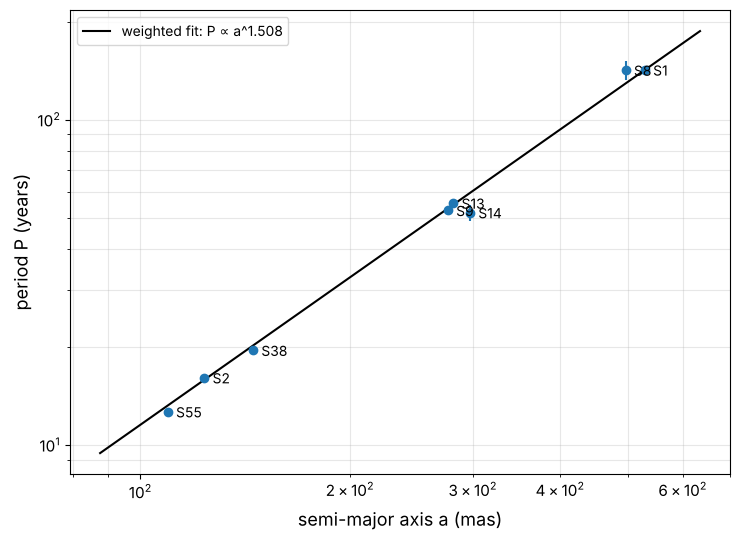

stars used: ['S1', 'S8', 'S9', 'S13', 'S14', 'S38', 'S55', 'S2']
slope = 1.508;  a³/P² = 7350 mas³/yr²  ->  M = 4.55 million M_sun at R0 = 8.53 kpc


S1     7339.0
S8     6085.0
S9     7615.0
S13    7243.0
S14    9784.0
S38    8007.0
S55    8203.0
S2     7282.0
dtype: float64

In [44]:
# Keep the stars whose a³/P² is measured to better than ~15% AND whose data cover
# at least 15% of their orbit (the covariance is only a local approximation and can
# be badly over-confident for a barely sampled orbit). Weight by precision.
coverage = (star_orbits["covered"] / star_orbits["P"]).fillna(1.0)
good = star_orbits[(star_orbits["sigma_log_mu"] < 0.15) & (coverage > 0.15)].copy()
good.loc["S2", "sigma_log_mu"] = 0.02           # S2's own uncertainty, from the bootstrap
weights = 1 / good["sigma_log_mu"] ** 2
X3 = np.log(good[["a"]].values)
y3 = np.log(good["P"].values)
law3 = LinearRegression().fit(X3, y3, sample_weight=weights)
log_mu = 3 * X3.ravel() - 2 * y3                   # log(a³/P²) for every star
mu_stars = np.exp(np.average(log_mu, weights=weights))
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.errorbar(good["a"], good["P"], yerr=good["P"] * good["sigma_log_mu"] / 2, fmt="o")
for star, row in good.iterrows():
    ax.annotate(star, (row["a"], row["P"]), xytext=(6, -4), textcoords="offset points")
aa = np.logspace(np.log10(good["a"].min() * 0.8), np.log10(good["a"].max() * 1.2), 50)
ax.plot(aa, np.exp(law3.predict(np.log(aa).reshape(-1, 1))), "k-",
        label=f"weighted fit: P ∝ a^{law3.coef_[0]:.3f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("semi-major axis a (mas)"); ax.set_ylabel("period P (years)")
ax.grid(alpha=0.3, which="both"); ax.legend()
save_fig("sstars_third_law_plot")
plt.show()
print(f"stars used: {list(good.index)}")
print(f"slope = {law3.coef_[0]:.3f};  a³/P² = {mu_stars:.4g} mas³/yr²  ->  "
      f"M = {mu_stars * best['R0']**3 / 1e6:.2f} million M_sun at R0 = {best['R0']:.2f} kpc")
pd.Series(np.exp(log_mu), index=good.index).round(0)

## Launch, Monitor, and Maintain Your System

In [45]:
next_peri = best["t_peri"] + best["P"]
boot_next = []
rng = np.random.RandomState(0)
print(f"predicted next pericentre passage of S2: {next_peri:.3f}")
t18 = np.linspace(2017.5, 2019.0, 1000)
ra18, dec18, rv18 = orbit_model(q, t18)
print(f"predicted radial velocity range in 2018: {rv18.min():.0f} to {rv18.max():.0f} km/s")
print(f"closest projected approach in 2018: {np.hypot(ra18 - best['x0'], dec18 - best['y0']).min():.1f} mas")

predicted next pericentre passage of S2: 2018.406
predicted radial velocity range in 2018: -1769 to 4063 km/s
closest projected approach in 2018: 10.7 mas


In [46]:
# Monitoring for 'concept drift': what does Einstein add on top of Kepler?
beta = v_peri / c
grav_redshift = G * M / (r_peri * c**2) * c / 1e3            # km/s
transverse_doppler = 0.5 * beta**2 * c / 1e3                 # km/s
precession = 6 * np.pi * G * M / (c**2 * a_AU * AU * (1 - best["e"]**2))   # rad per orbit
print(f"gravitational redshift at pericentre ≈ {grav_redshift:.0f} km/s")
print(f"transverse Doppler shift             ≈ {transverse_doppler:.0f} km/s")
print(f"Schwarzschild precession per orbit   ≈ {np.degrees(precession) * 60:.1f} arcmin")

gravitational redshift at pericentre ≈ 107 km/s
transverse Doppler shift             ≈ 101 km/s
Schwarzschild precession per orbit   ≈ 12.3 arcmin


In [47]:
import json
os.makedirs("animations", exist_ok=True)
anim = {"s2": {k: float(v) for k, v in best.items()},
        "M_million": float(black_hole_mass(best) / 1e6),
        "stars": {s: {k: float(star_orbits.loc[s, k]) for k in ["a", "e", "i", "Omega", "omega", "t_peri", "P"]}
                  for s in good.index},
        "s2_astrometry": s2[s2["kind"] == "a"][["date", "x", "y", "x_err", "y_err"]].round(2).values.tolist(),
        "s2_rv": s2[s2["kind"] == "rv"][["date", "rv", "rv_err"]].round(1).values.tolist()}
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f)
print({k: round(v, 3) for k, v in anim["s2"].items()})

{'a': 123.503, 'e': 0.882, 'i': 135.11, 'Omega': 225.86, 'omega': 64.266, 't_peri': 2002.323, 'P': 16.084, 'R0': 8.526, 'x0': 0.529, 'y0': -0.338, 'vx': 0.0, 'vy': 0.0, 'vz0': 30.495}
